# Пол клиента по транзакциям

| | ROC AUC | Accuracy |
|---|---|---|
| Кросс-валидация, train+val (2×5 фолдов) | 0.8907 ± 0.0121 | 0.8044 ± 0.0132 |
| **Test**, 1 680 клиентов, 95% CI | **0.898 [0.883; 0.913]** ✓ | **0.811 [0.793; 0.830]** ✓ |
| Требование задания | > 0.88 | > 0.80 |

**Подход**
1. Клиентские агрегаты (MCC-профиль, суммы, время, динамика) + признаки с метками, считаемые только внутри обучения → LightGBM.
2. Энкодер CoLES: контрастное предобучение GRU на последовательностях транзакций без меток, затем дообучение на пол; его эмбеддинг — ещё и признак для бустинга.
3. TabPFN на отобранных признаках; калиброванный бленд трёх моделей в пространстве логитов, порог 0.5.


**Содержание:** 1. Данные · 2. Признаки · 3. CoLES · 4. Модели и бленд · 5. Финальная оценка · 6. Выводы

In [1]:
import os
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir("..")

import matplotlib.pyplot as plt
import pandas as pd

from gender_pred import cli, plots
from gender_pred.cv import bootstrap_ci
from gender_pred.data import download_data, labels, load_config

RETRAIN = False  # True — полный пересчёт (~1 ч на GPU); False — финальные модели из artifacts/ (GitHub Release)
cfg = load_config("configs/default.yaml", retrain=RETRAIN)
plots.style()

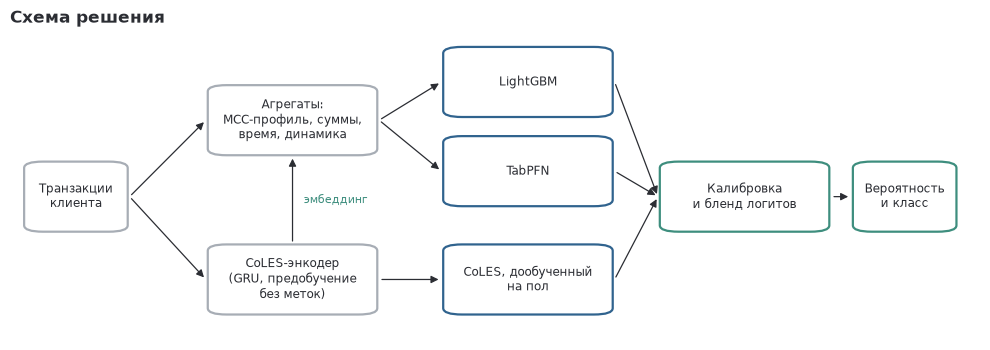

In [2]:
fig = plots.pipeline_schema()

## 1. Данные

Датасет `mks-logic/gender_prediction`: транзакции 8 400 клиентов, разбиение по клиентам на train / val / test.
Окружение и пакет ставятся командой `make setup`; данные скачиваются, если их ещё нет.

In [3]:
download_data(cfg["paths"]["data"])

In [4]:
def load_dataset(splits=["train", "val", "test"], path="data/"):
    dataset = {}
    for split in splits:
        df = pd.read_csv(f"{path}{split}.csv")
        df["term_id"] = df["term_id"].fillna(-1)
        df['gender_desc'] = df.gender.map({0: "женщина", 1: "мужчина"})
        df['tr_datetime'] = pd.to_datetime(df['tr_datetime'], errors='coerce')
        df.sort_values(['customer_id', 'tr_datetime'], inplace=True)
        dataset[split] = df
    return dataset

dataset = load_dataset()

train_df = dataset["train"]
train_df.head(2)

,customer_id,tr_datetime,mcc_code,tr_type,amount,term_id,gender,tr_type_desc,mcc_code_desc,gender_desc
0,0,2000-01-01 10:23:26,0,0,-2245.92,-1,1,Оплата услуги. Банкоматы СБ РФ,"Звонки с использованием телефонов, считывающих...",мужчина
1,0,2000-01-02 10:19:29,1,1,56147.89,-1,1,Взнос наличных через АТМ (в своем тер.банке),Финансовые институты — снятие наличности автом...,мужчина


In [5]:
for split in ["train", "test", "val"]:
    print(f"{split.upper()} split: ", dataset[split]["customer_id"].nunique(), " customers")

TRAIN split:  5880  customers
TEST split:  1680  customers
VAL split:  840  customers


In [6]:
def plot_top_counts(series, top_n=20, xlabel="Count", ylabel=""):
    counts = series.value_counts()
    top_items = counts.nlargest(top_n)
    plt.figure(figsize=(8,6))
    plt.barh(top_items.index, top_items.values)
    plt.xlabel(xlabel)
    plt.ylabel(ylabel)
    plt.show()

Главный источник сигнала — **на что** клиент тратит. Ниже — MCC с наибольшим отклонением доли мужчин
от средней (только train, MCC с ≥ 200 клиентами).

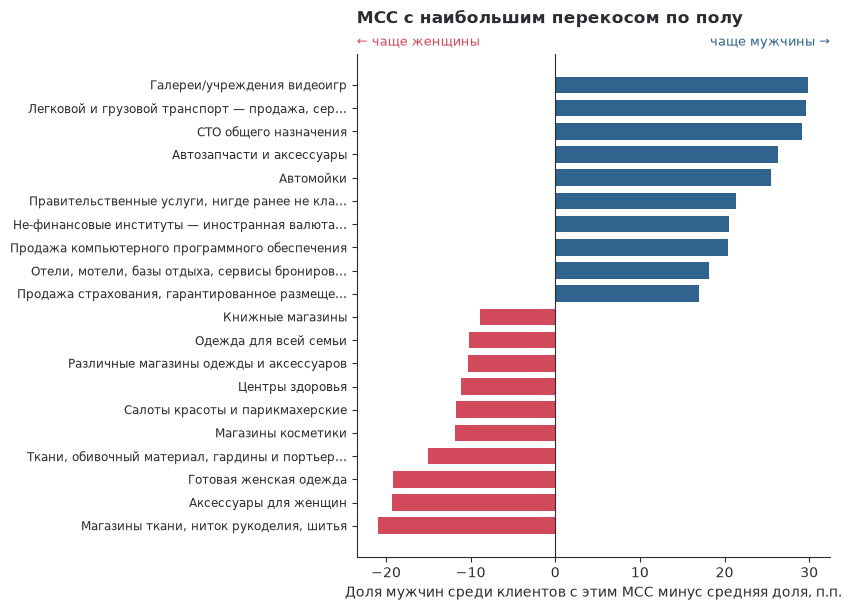

In [7]:
fig = plots.mcc_gender_skew(cfg)

**Вывод.** Перекос по полу сильный и интерпретируемый: «Магазины ткани, ниток рукоделия, шитья» — доля мужчин
на 21 п.п. ниже средней, «Галереи/учреждения видеоигр» — на 30 п.п. выше.
Ещё два наблюдения из EDA учтены в признаках: 12% операций имеют время ровно 00:00:00 (это «время неизвестно»,
а не полночь), а суммы отмасштабированы — «круглых» сумм в данных нет.

### Бейзлайн задания

In [8]:
def baseline_aggregation(df):
    tx_stats = df.groupby('customer_id').agg({
        'amount': ['count', 'sum'],
        'mcc_code': pd.Series.nunique,
        'tr_type': pd.Series.nunique,
    })
    tx_stats.columns = [f'base_{k}_{stat}' for k, stat in tx_stats.columns]
    tx_stats.reset_index(inplace=True)

    target = df[['customer_id', 'gender']].drop_duplicates()
    features = tx_stats.merge(target, on='customer_id', how='left')

    X = features.drop(columns=['customer_id', 'gender'])
    y = features['gender']

    return X, y

X_train, y_train = baseline_aggregation(dataset["train"])
X_test, y_test = baseline_aggregation(dataset["test"])
X_val, y_val = baseline_aggregation(dataset["val"])

assert X_train.shape[1] == X_val.shape[1] == X_test.shape[1]

In [9]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_auc_score, accuracy_score, average_precision_score,
    precision_score, recall_score
)

def eval(y_val, y_pred, y_pred_proba):
    auc = roc_auc_score(y_val, y_pred_proba)
    acc = accuracy_score(y_val, y_pred)
    precision = precision_score(y_val, y_pred)
    recall = recall_score(y_val, y_pred)

    return {
        "auc_score": auc,
        "accuracy_score": acc,
        "precision_score": precision,
        "recall_score": recall
    }

def fit_predict_rf(X_train, y_train, X_val, y_val, X_test):
    model = RandomForestClassifier(n_estimators=100, random_state=42)
    model.fit(X_train, y_train)

    y_pred_proba = model.predict_proba(X_test)[:, 1]
    y_pred = (y_pred_proba >= 0.5).astype(int)

    return y_pred_proba, y_pred

y_pred_proba, y_pred = fit_predict_rf(X_train, y_train, X_val, y_val, X_test)
metrics = eval(y_test, y_pred, y_pred_proba)
metrics

{'auc_score': 0.5737087280045527,
 'accuracy_score': 0.5577380952380953,
 'precision_score': 0.5238095238095238,
 'recall_score': 0.4269081500646831}

## 2. Признаки

На клиента считается ~719 признаков без меток — одинаковые колонки на любом сплите (словари категорий
фиксируются по train): активность, суммы расходов и поступлений, **профиль MCC** (доли операций и трат, средний
чек), профиль типов операций, время (часы с учётом «неизвестного» времени, дни недели), терминалы и динамика
(концентрация трат, затухающие средние, автокорреляция, окна последних 30/90/180 дней).

Признаки с метками — target encoding MCC и типов операций, логрег по TF-IDF профилей и логрег по эмбеддингу
CoLES — считаются **только внутри обучения**: для обучающих клиентов out-of-fold по внутренним фолдам,
для новых — по статистикам обучающих. Test в их расчёте не участвует.

In [10]:
imp = pd.read_csv("results/feature_importance.csv")
groups = {"mcc": "MCC-профиль", "lr": "Линейные модели (TF-IDF, CoLES)", "te": "Target encoding",
          "time": "Время", "dyn": "Динамика", "amt": "Суммы", "tt": "Типы операций", "act": "Активность",
          "term": "Терминалы"}
share = imp.groupby(imp.feature.str.split("_").str[0]).gain_share.sum().sort_values(ascending=False)
share.rename(groups).mul(100).round(1).to_frame("доля gain, %")

,"доля gain, %"
feature,
"Линейные модели (TF-IDF, CoLES)",27.4
MCC-профиль,19.1
Target encoding,17.7
Время,10.8
Динамика,9.4
Суммы,7.1
Типы операций,5.0
Активность,2.3
Терминалы,1.3


**Вывод.** Больше всего gain у групп «линейные модели (TF-IDF, CoLES)» (27%), «MCC-профиль» (19%) и «target encoding» (18%); терминалы почти не используются (1.3%) — у медианного терминала один клиент.

## 3. CoLES

Энкодер — GRU над транзакциями (MCC, тип операции, сумма, час, день недели, интервал между операциями).
Предобучение без меток (CoLES): случайные срезы одного клиента сближаются в пространстве эмбеддингов,
срезы разных клиентов — отталкиваются. Затем энкодер (а) даёт эмбеддинг клиента и (б) дообучается на пол.
Для предобучения используются только клиенты train и val.

In [11]:
ctx = cli.build_context(cfg, dataset, log=False)
print(f"устройство: {ctx.device}; клиентов с последовательностями: {len(ctx.seqs.ids)}")

устройство: cuda; клиентов с последовательностями: 8400


**Вывод.** Эмбеддинг CoLES сам по себе даёт AUC ≈ 0.866 у дообученного энкодера —
меньше, чем агрегаты, но сигнал частично независимый: в бленде он стабильно добавляет качество (раздел 4).
В двумерной проекции (UMAP) пол визуально не разделяется — сигнал распределён по многим измерениям,
поэтому проекцию не показываем.

## 4. Модели и бленд

Три модели оцениваются на одной кросс-валидации (train+val, stratified 5-fold × 2 повтора): число итераций
бустинга, калибровка и веса бленда для каждого фолда подбираются по остальным фолдам.

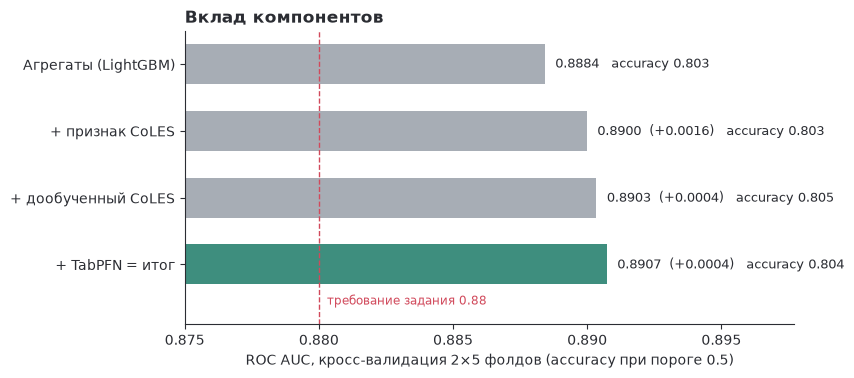

In [12]:
fig = plots.component_contribution(cfg)

**Вывод.** Агрегаты с LightGBM дают 0.8884; признак CoLES и дообученный энкодер добавляют
сигнал о порядке операций, которого нет в агрегатах; итог — **0.8907** (accuracy
0.804). Веса бленда: gbm 0.70, seq 0.10, tabpfn 0.20.

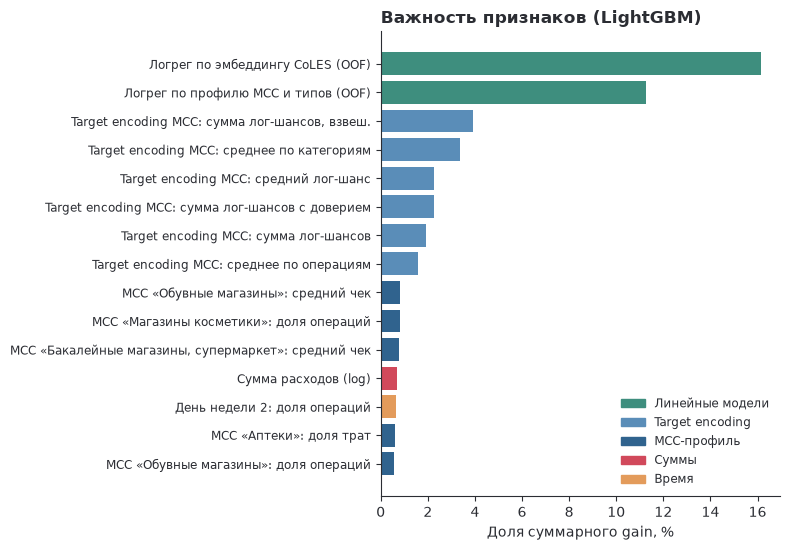

In [13]:
fig = plots.feature_importance(cfg)

**Вывод.** Сильнейшие признаки — сводные оценки профиля трат (логрег по TF-IDF MCC, target encoding MCC)
и доли конкретных MCC; заметный вклад у времени операций и динамики трат. Топ-15 признаков дают
48% суммарного gain.

Проверено и не вошло: target encoding и граф клиент–терминал, CatBoost и XGBoost, дополнительные статистики
концентрации и ритма трат — прирост в пределах шума фолдов.

## 5. Финальная оценка

Ячейки шаблона: признаки считаются на каждом сплите отдельно, модель обучается на train+val, test только
предсказывается. При `RETRAIN = False` загружаются финальные модели из `artifacts/`.

In [14]:
def generate_features(df):
    """Агрегаты клиента + эмбеддинг CoLES (index = customer_id); последовательности — в хранилище пакета."""
    X = ctx.features(df)
    y = labels(df).reindex(X.index)
    return X, y


def fit_predict_proba(X_train, y_train, X_val, y_val, X_test):
    """LightGBM + дообученный CoLES + TabPFN, калиброванный бленд; порог 0.5."""
    return cli.fit_predict(ctx, X_train, y_train, X_val, y_val, X_test)

In [15]:
# Feature engineering
X_train, y_train = generate_features(dataset["train"])
X_test, y_test = generate_features(dataset["test"])
X_val, y_val = generate_features(dataset["val"])

assert X_train.shape[1] == X_val.shape[1] == X_test.shape[1]

# Model training and prediction
y_pred_proba, y_pred = fit_predict_proba(X_train, y_train, X_val, y_val, X_test)

# Evaluation
metrics = eval(y_test, y_pred, y_pred_proba)
metrics

{'auc_score': 0.8979020440415284,
 'accuracy_score': 0.8113095238095238,
 'precision_score': 0.8343108504398827,
 'recall_score': 0.7360931435963778}

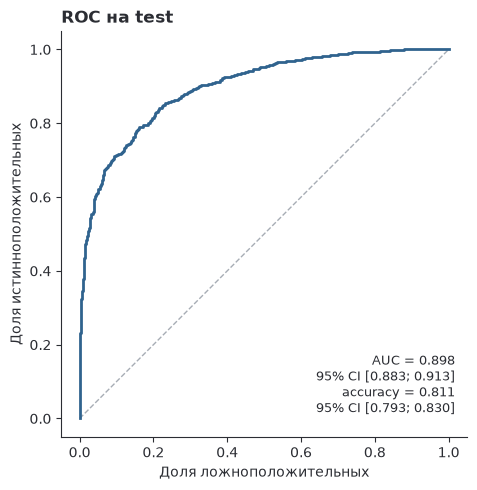

In [16]:
m = bootstrap_ci(y_test.to_numpy(), y_pred_proba, threshold=0.5, n=cfg["report"]["bootstrap"])
pd.DataFrame({"gender": y_test.to_numpy(), "proba": y_pred_proba}, index=y_test.index).to_parquet(
    "results/test_predictions.parquet")
fig = plots.roc_test(cfg)

**Вывод.** На test AUC = **0.8979** (95% CI 0.883–0.913),
accuracy = **0.8113** (95% CI 0.793–0.830):
требования ✓ AUC > 0.88 и ✓ accuracy > 0.80.
Ширина интервалов (±0.015 по AUC на 1 680 клиентах) больше, чем
разница между сильными вариантами модели, поэтому решения принимались только по кросс-валидации.

## 6. Выводы

- Решающий сигнал — **профиль трат по MCC**: одна эта группа поднимает AUC с ~0.67 до ~0.88; остальные
  агрегаты и модели добавляют ещё ≈ 0.011.
- **CoLES** полезен как дополнение к агрегатам (эмбеддинг-признак и дообученная модель в бленде), но не как
  замена: на 8 400 клиентах предобучению не хватает объёма неразмеченных последовательностей.
- **Бленд в пространстве логитов с калибровкой** даёт честные вероятности, поэтому порог 0.5 оптимален для
  accuracy без подбора на test.
- Test открывался один раз, на зафиксированной модели; итог: AUC 0.8979, accuracy 0.8113.
- Что дальше: больше неразмеченных последовательностей для предобучения CoLES, трансформер вместо GRU,
  мультизадачное дообучение (пол + возраст/доход при наличии разметки).